<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/Pembelajaran_Mesin_2026/blob/main/Kuis1_ML_EDA_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



```
# This is formatted as code
```

# 📊 Kuis 1 Machine Learning - EDA & Preprocessing
Soal kuis berbasis dataset TI-3B. Buat dataset TI-3B dengan fitur sebagai berikut: nama lengkap, jenis kelamin, kota asal, tinggi badan(cm), asal kelas, target IP semester 5, warna kesukaan, hobi, film favorit, warna favorit, genre musik, idola, kota favorit, makanan favorit, minuman favorit, negara yang ingin dikunjungi.
Silakan kerjakan langsung di Colab dengan mengisi kode dan jawabanmu.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
file_path = "/content/Dataset TI-3B - Sheet1.csv"
df = pd.read_csv(file_path)

# Tampilkan 10 data awal
df.head()

,no,nama_lengkap,jenis_kelamin,kota_asal,tinggi_badan_(cm),asal_kelas,target_ip_smt_5,warna_kesukaan,hobi,film_fav,genre_musik,idola,kota_fav,makanan_fav,minuman_fav,negara_yang_ingin_dikunjungi
0,1,Alfreda Dhaifullah Mahezwara,L,Malang,172,2C,4,Red Marron,Main ML,The Shadow Edge,Britpop,Jackable,"malang,batu",Nasi Goreng,Es Teler,China
1,2,Angga Saputra Ramadhan,L,Probolinggo,163,2B,4,Putih,Sepak Bola,Semua,Electropop,Neymar Jr,Malang,Ayam Geprek,Capuccino,Thailand
2,3,Ardhan Dikri Achmad Fahrudin,L,Malang,172,2H,4,Biru,Basket,Toy Story,Pop,Messi,Labuan Bajo,Tahu Telor,Hot V60,Swiss
3,4,Arjuna Carly Dhymas Mahendra,L,Sidoarjo,165,2B,4,Biru,Basket,Seven,Rock,Ronaldo,Bandung,Sate Ayam,Air Mineral,Swiss
4,5,Arya Ramadhan,L,Malang,175,2G,4,Ungu,Berenang,Lucifer (2016-2021)`,Pop,Diana Rider,Malang,Oyi Buttermilk,KAPITEN,UK


## Soal 1
Hitung rata-rata tinggi badan mahasiswa **yang asal kotanya sama dengan kamu**.

- Bersihkan data asal kota dulu, jika ada data yang berisi "kota madiun", "kabupaten malang" bersihkan hingga hanya menjadi "madiun" dan "malang"
- Bandingkan tinggi badanmu dengan rata-rata kota asal.
- Apakah kamu lebih tinggi atau lebih rendah dari rata-rata tersebut?

In [ ]:
# Jawaban Soal 1
import pandas as pd
import numpy as np

# Load data
df = pd.read_csv('Dataset TI-3B - Sheet1.csv')

# Cleaning kolom kota_asal
df['kota_asal_clean'] = df['kota_asal'].str.lower().str.strip()

# Cek unique kota asal setelah cleaning
print(df['kota_asal_clean'].unique())
print ()

# Filter mahasiswa dari Malang
df_malang = df[df['kota_asal_clean'] == 'malang']

print("Jumlah mahasiswa asal Malang:", len(df_malang))
print(df_malang[['no', 'nama_lengkap', 'tinggi_badan_(cm)']])

# Hitung rata-rata
rata_malang = df_malang['tinggi_badan_(cm)'].mean()
print(f"\nRata-rata tinggi badan mahasiswa asal Malang: {rata_malang:.2f} cm")

['malang' 'probolinggo' 'sidoarjo' 'nganjuk' 'blitar' 'bali' 'banyuwangi'
 'pasuruan' 'tulungagung' 'jakarta' 'bojonegoro' 'denpasar' 'bondowoso']

Jumlah mahasiswa asal Malang: 7
    no                    nama_lengkap  tinggi_badan_(cm)
0    1    Alfreda Dhaifullah Mahezwara                172
2    3    Ardhan Dikri Achmad Fahrudin                172
4    5                   Arya Ramadhan                175
6    7      Bagus Wichaksono Amanulloh                178
10  11            Difa Naya Sari Pasha                170
20  21  Savero Athallah Hardiana Putra                180
22  23      Tsabita Keizya Vanya Putri                160

Rata-rata tinggi badan mahasiswa asal Malang: 172.43 cm


In [ ]:
#Jawaban soal 1

tinggi_no1 = df.loc[df['no'] == 1, 'tinggi_badan_(cm)'].values[0]
print(f"Tinggi badan Alfreda: {tinggi_no1} cm")
print(f"Rata-rata Malang: {rata_malang:.2f} cm")

if tinggi_no1 > rata_malang:
    print("Kesimpulan: Lebih TINGGI dari rata-rata")
elif tinggi_no1 < rata_malang:
    print("Kesimpulan: Lebih RENDAH dari rata-rata")
else:
    print("Kesimpulan: SAMA dengan rata-rata")

#hasil

Tinggi badan Alfreda: 172 cm
Rata-rata Malang: 172.43 cm
Kesimpulan: Lebih RENDAH dari rata-rata


## Soal 2
Kolom **Target IP semester 5 ini** memiliki variasi format (angka, teks, koma/titik).

- Bersihkan kolom menjadi numerik.
- Lakukan normalisasi Min-Max.
- Berapa nilai normalisasi IPS target kamu sendiri?

In [ ]:
# Jawaban Soal 2

print(df['target_ip_smt_5'].unique())
print(df['target_ip_smt_5'].dtype)

# clean data
def clean_numeric(val):
    if pd.isna(val):
        return np.nan
    # Ubah ke string, ganti koma jadi titik, hapus karakter non-numerik
    s = str(val).strip().replace(',', '.')
    # Ambil hanya angka, titik, dan minus
    s = ''.join(c for c in s if c.isdigit() or c == '.' or c == '-')
    try:
        return float(s)
    except:
        return np.nan

# min max data
df['target_ip_clean'] = df['target_ip_smt_5'].apply(clean_numeric)

print(df[['no', 'nama_lengkap', 'target_ip_smt_5', 'target_ip_clean']].head())
print("\nDtype:", df['target_ip_clean'].dtype)
print("Min:", df['target_ip_clean'].min())
print("Max:", df['target_ip_clean'].max())


x_min = df['target_ip_clean'].min()
x_max = df['target_ip_clean'].max()
print()

df['target_ip_norm'] = (df['target_ip_clean'] - x_min) / (x_max - x_min)

print(f"Min: {x_min}, Max: {x_max}")
print(df[['no', 'nama_lengkap', 'target_ip_clean', 'target_ip_norm']].head())

[4]
int64
   no                  nama_lengkap  target_ip_smt_5  target_ip_clean
0   1  Alfreda Dhaifullah Mahezwara                4              4.0
1   2        Angga Saputra Ramadhan                4              4.0
2   3  Ardhan Dikri Achmad Fahrudin                4              4.0
3   4  Arjuna Carly Dhymas Mahendra                4              4.0
4   5                 Arya Ramadhan                4              4.0

Dtype: float64
Min: 4.0
Max: 4.0

Min: 4.0, Max: 4.0
   no                  nama_lengkap  target_ip_clean  target_ip_norm
0   1  Alfreda Dhaifullah Mahezwara              4.0             NaN
1   2        Angga Saputra Ramadhan              4.0             NaN
2   3  Ardhan Dikri Achmad Fahrudin              4.0             NaN
3   4  Arjuna Carly Dhymas Mahendra              4.0             NaN
4   5                 Arya Ramadhan              4.0             NaN


## Soal 3
Lakukan **Label Encoding** pada kolom **Warna kesukaan**.

- Tampilkan hasil encoding warna kesukaanmu sendiri.
- Apakah warnamu termasuk kode terkecil, terbesar, atau di tengah?

In [ ]:
# Jawaban Soal 3

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['warna_encoded'] = le.fit_transform(df['warna_kesukaan'])

# Tampilkan mapping
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Mapping Label Encoding:")
for warna, kode in sorted(mapping.items(), key=lambda x: x[1]):
    print(f"  {kode} -> {warna}")

print ()
alfreda = df[df['no'] == 1]
print(alfreda[['no', 'nama_lengkap', 'warna_kesukaan', 'warna_clean', 'warna_encoded']])

#Hasil

Mapping Label Encoding:
  0 -> Abu
  1 -> Biru
  2 -> Biru 
  3 -> Biru Tua
  4 -> Hitam
  5 -> Kuning
  6 -> Maroon
  7 -> Merah Muda
  8 -> Pink
  9 -> Putih
  10 -> Red Marron
  11 -> Ungu
  12 -> biru
  13 -> marron
  14 -> putih

   no                  nama_lengkap warna_kesukaan warna_clean  warna_encoded
0   1  Alfreda Dhaifullah Mahezwara     Red Marron  red marron             10


## Soal 4
Kelompokkan data berdasarkan **Jenis kelamin**.

- Hitung rata-rata tinggi badan tiap kelompok.
- Bandingkan tinggi badanmu dengan rata-rata kelompokmu.

In [ ]:
# Jawaban Soal 4

print("Nilai unik jenis_kelamin:")
print(df['jenis_kelamin'].unique())
print("\nJumlah per kelompok:")
print(df['jenis_kelamin'].value_counts())
print()


# hitung rata-rata tinggi badan per kelompok
rata_kelompok = df.groupby('jenis_kelamin')['tinggi_badan_(cm)'].agg(['mean', 'min', 'max', 'count'])

print("Rata-rata tinggi badan per jenis kelamin:")
print(rata_kelompok)


# Ambil data Saya
tinggi_alfreda = df.loc[df['no'] == 1, 'tinggi_badan_(cm)'].values[0]
jk_alfreda = df.loc[df['no'] == 1, 'jenis_kelamin'].values[0]

# Rata-rata kelompok Laki laki
rata_kelompok_alfreda = df[df['jenis_kelamin'] == jk_alfreda]['tinggi_badan_(cm)'].mean()

print(f"Jenis kelamin Alfreda: {jk_alfreda}")
print(f"Tinggi Alfreda: {tinggi_alfreda} cm")
print(f"Rata-rata kelompok {jk_alfreda}: {rata_kelompok_alfreda:.2f} cm")
print(f"Selisih: {tinggi_alfreda - rata_kelompok_alfreda:+.2f} cm")

if tinggi_alfreda > rata_kelompok_alfreda:
    print("→ Alfreda LEBIH TINGGI dari rata-rata kelompoknya")
elif tinggi_alfreda < rata_kelompok_alfreda:
    print("→ Alfreda LEBIH RENDAH dari rata-rata kelompoknya")
else:
    print("→ Alfreda SAMA dengan rata-rata kelompoknya")
#Hasil

Nilai unik jenis_kelamin:
['L' 'P']

Jumlah per kelompok:
jenis_kelamin
L    18
P     7
Name: count, dtype: int64

Rata-rata tinggi badan per jenis kelamin:
                     mean  min  max  count
jenis_kelamin                             
L              171.888889  160  180     18
P              157.857143  150  170      7
Jenis kelamin Alfreda: L
Tinggi Alfreda: 172 cm
Rata-rata kelompok L: 171.89 cm
Selisih: +0.11 cm
→ Alfreda LEBIH TINGGI dari rata-rata kelompoknya


## Soal 5 (pilih 2 fitur dari fitur yang ada)
Selanjutnya buat bar chart distribusi (misal)**Makanan favorit dan minuman favorit**.

- Dari grafik tersebut, apakah makanan dan minuman favoritmu termasuk dominan atau minoritas?

Kota asal unik: ['malang' 'probolinggo' 'sidoarjo' 'nganjuk' 'blitar' 'bali' 'banyuwangi'
 'pasuruan' 'tulungagung' 'jakarta' 'bojonegoro' 'denpasar' 'bondowoso']

Negara unik: ['china' 'thailand' 'swiss' 'uk' 'jepang' 'australia' 'austria' 'mongolia'
 'islandia' 'findlandia' 'spanyol' 'usa' 'arab saudi' 'brunei darussalam'
 'new zealand' 'jerman']


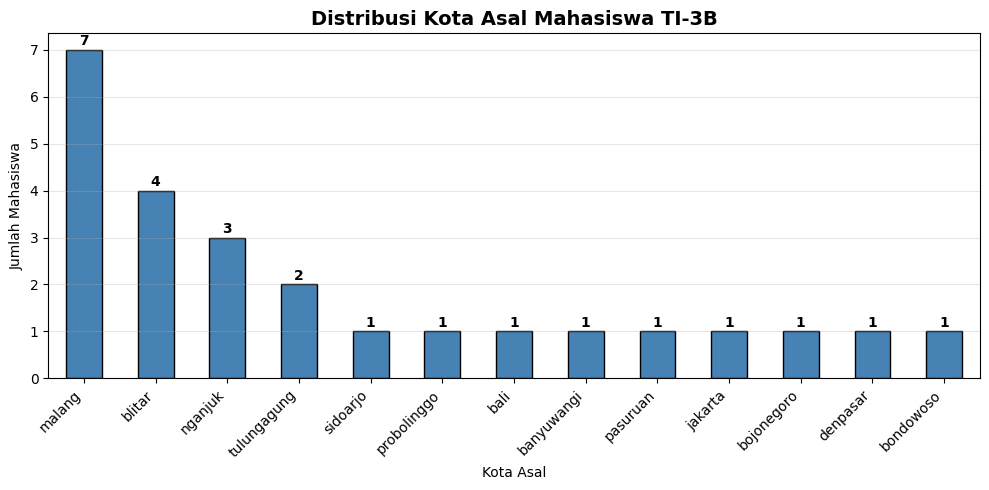

kota_asal_clean
malang         7
blitar         4
nganjuk        3
tulungagung    2
sidoarjo       1
probolinggo    1
bali           1
banyuwangi     1
pasuruan       1
jakarta        1
bojonegoro     1
denpasar       1
bondowoso      1
Name: count, dtype: int64


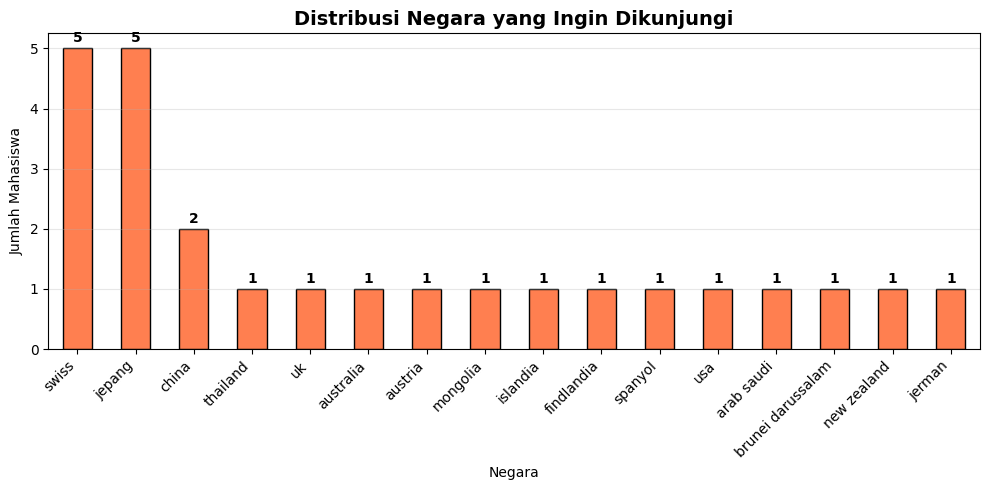

negara_clean
swiss                5
jepang               5
china                2
thailand             1
uk                   1
australia            1
austria              1
mongolia             1
islandia             1
findlandia           1
spanyol              1
usa                  1
arab saudi           1
brunei darussalam    1
new zealand          1
jerman               1
Name: count, dtype: int64
ANALISIS KOTA ASAL
Kota paling dominan: malang (7 orang, 28.0%)
Jumlah kota unik: 13
Kota minoritas (1 orang): 9 kota

ANALISIS NEGARA TUJUAN
Negara paling dominan: swiss (5 orang, 20.0%)
Jumlah negara unik: 16
Negara minoritas (1 orang): 13 negara


In [ ]:
# Jawaban Soal 5

import pandas as pd
import matplotlib.pyplot as plt


# Cleaning kota_asal
df['kota_asal_clean'] = df['kota_asal'].str.lower().str.strip()

# Cleaning negara_yang_ingin_dikunjungi
df['negara_clean'] = df['negara_yang_ingin_dikunjungi'].str.lower().str.strip()

print("Kota asal unik:", df['kota_asal_clean'].unique())
print("\nNegara unik:", df['negara_clean'].unique())


# Hitung frekuensi kota asal
kota_counts = df['kota_asal_clean'].value_counts()

plt.figure(figsize=(10, 5))
kota_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Distribusi Kota Asal Mahasiswa TI-3B', fontsize=14, fontweight='bold')
plt.xlabel('Kota Asal')
plt.ylabel('Jumlah Mahasiswa')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Tambahkan label angka di atas bar
for i, v in enumerate(kota_counts.values):
    plt.text(i, v + 0.1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print(kota_counts)

negara_counts = df['negara_clean'].value_counts()

plt.figure(figsize=(10, 5))
negara_counts.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Distribusi Negara yang Ingin Dikunjungi', fontsize=14, fontweight='bold')
plt.xlabel('Negara')
plt.ylabel('Jumlah Mahasiswa')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

for i, v in enumerate(negara_counts.values):
    plt.text(i, v + 0.1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print(negara_counts)


# analisis dominan vs minoritas
print("=" * 50)
print("ANALISIS KOTA ASAL")
print("=" * 50)
total = len(df)
top_kota = kota_counts.idxmax()
top_kota_count = kota_counts.max()
print(f"Kota paling dominan: {top_kota} ({top_kota_count} orang, {top_kota_count/total*100:.1f}%)")
print(f"Jumlah kota unik: {len(kota_counts)}")
print(f"Kota minoritas (1 orang): {sum(kota_counts == 1)} kota")

print("\n" + "=" * 50)
print("ANALISIS NEGARA TUJUAN")
print("=" * 50)
top_negara = negara_counts.idxmax()
top_negara_count = negara_counts.max()
print(f"Negara paling dominan: {top_negara} ({top_negara_count} orang, {top_negara_count/total*100:.1f}%)")
print(f"Jumlah negara unik: {len(negara_counts)}")
print(f"Negara minoritas (1 orang): {sum(negara_counts == 1)} negara")
#Hasil

## Soal 6
Gunakan metode **IQR (Interquartile Range)** untuk mendeteksi outlier tinggi badan.

- Apakah tinggi badanmu termasuk outlier atau tidak?

In [ ]:
# Jawaban Soal 6

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Dataset TI-3B - Sheet1.csv')

# Kolom tinggi badan
tinggi = df['tinggi_badan_(cm)']

# Hitung Q1, Q3, IQR
Q1 = tinggi.quantile(0.25)
Q3 = tinggi.quantile(0.75)
IQR = Q3 - Q1

# Batas bawah & atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas  = Q3 + 1.5 * IQR

print(f"Q1           : {Q1}")
print(f"Q3           : {Q3}")
print(f"IQR          : {IQR}")
print(f"Batas bawah  : {batas_bawah}")
print(f"Batas atas   : {batas_atas}")

# Deteksi outlier
df['is_outlier'] = (tinggi < batas_bawah) | (tinggi > batas_atas)

print("\nData outlier:")
print(df[df['is_outlier']][['no', 'nama_lengkap', 'tinggi_badan_(cm)']])
print(f"\nJumlah outlier: {df['is_outlier'].sum()}")


# cek data saya termasuk outlier atau tidak

tinggi_alfreda = df.loc[df['no'] == 1, 'tinggi_badan_(cm)'].values[0]

print(f"Tinggi Alfreda : {tinggi_alfreda} cm")
print(f"Batas bawah    : {batas_bawah} cm")
print(f"Batas atas     : {batas_atas} cm")

if tinggi_alfreda < batas_bawah or tinggi_alfreda > batas_atas:
    print("→ Alfreda TERMASUK OUTLIER")
else:
    print("→ Alfreda TIDAK termasuk outlier")

#Hasil

Q1           : 160.0
Q3           : 175.0
IQR          : 15.0
Batas bawah  : 137.5
Batas atas   : 197.5

Data outlier:
Empty DataFrame
Columns: [no, nama_lengkap, tinggi_badan_(cm)]
Index: []

Jumlah outlier: 0
Tinggi Alfreda : 172 cm
Batas bawah    : 137.5 cm
Batas atas     : 197.5 cm
→ Alfreda TIDAK termasuk outlier


## Soal 7
Bersihkan kolom **Asal kelas** (hapus spasi berlebih, seragamkan huruf kapitalisasi).

- Hitung jumlah mahasiswa per kelas.
- Apakah kamu termasuk di kelas dengan jumlah terbanyak, menengah, atau sedikit?

In [ ]:
# Jawaban Soal 7


# Cek isi kolom asal_kelas sebelum cleaning
print("Sebelum cleaning:")
print(df['asal_kelas'].unique())

# Cleaning: strip spasi & uppercase
df['asal_kelas_clean'] = df['asal_kelas'].str.strip().str.upper()

print("Setelah cleaning:")
print(df['asal_kelas_clean'].unique())

# Hitung frekuensi per kelas
kelas_counts = df['asal_kelas_clean'].value_counts().sort_index()

print("Jumlah mahasiswa per kelas:")
print(kelas_counts)

print("\nTotal mahasiswa:", kelas_counts.sum())


print("=" * 45)
print("KLASIFIKASI KELAS")
print("=" * 45)

maks = kelas_counts.max()
minim = kelas_counts.min()

for kelas, jumlah in kelas_counts.items():
    if jumlah == maks:
        kategori = "TERBANYAK"
    elif jumlah == minim:
        kategori = "PALING SEDIKIT"
    else:
        kategori = "MENENGAH"
    print(f"Kelas {kelas}: {jumlah} mahasiswa → {kategori}")



    # Ambil kelas Alfreda

kelas_alfreda = df.loc[df['no'] == 1, 'asal_kelas_clean'].values[0]
jumlah_kelas_alfreda = kelas_counts[kelas_alfreda]
print()
print(f"Alfreda (no 1) berasal dari kelas: {kelas_alfreda}")
print(f"Jumlah mahasiswa di kelas {kelas_alfreda}: {jumlah_kelas_alfreda}")

# Tentukan kategori
if jumlah_kelas_alfreda == maks:
    print("→ Alfreda berada di kelas dengan jumlah TERBANYAK")
elif jumlah_kelas_alfreda == minim:
    print("→ Alfreda berada di kelas dengan jumlah PALING SEDIKIT")
else:
    print("→ Alfreda berada di kelas dengan jumlah MENENGAH")
#Hasil

Sebelum cleaning:
['2C' '2B' '2H' '2G' '2E' '2A' '2F']
Setelah cleaning:
['2C' '2B' '2H' '2G' '2E' '2A' '2F']
Jumlah mahasiswa per kelas:
asal_kelas_clean
2A    4
2B    7
2C    6
2E    1
2F    2
2G    3
2H    2
Name: count, dtype: int64

Total mahasiswa: 25
KLASIFIKASI KELAS
Kelas 2A: 4 mahasiswa → MENENGAH
Kelas 2B: 7 mahasiswa → TERBANYAK
Kelas 2C: 6 mahasiswa → MENENGAH
Kelas 2E: 1 mahasiswa → PALING SEDIKIT
Kelas 2F: 2 mahasiswa → MENENGAH
Kelas 2G: 3 mahasiswa → MENENGAH
Kelas 2H: 2 mahasiswa → MENENGAH

Alfreda (no 1) berasal dari kelas: 2C
Jumlah mahasiswa di kelas 2C: 6
→ Alfreda berada di kelas dengan jumlah MENENGAH
